

#  Exploring Price Trends and Influential Factors Across Multiple agirucluture productCommodities in Nepal: A Data-Driven Analysis



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix,accuracy_score

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df = pd.read_csv("/content/drive/MyDrive/BigDataCourseWork/kalimati-tarkari-prices-from-may-2021-to-september-2023.csv")

In [ ]:
df.head()

,Tomato Big(Nepali),1/5/2021,Kg,50,60,55
0,Tomato Big(Indian),1/5/2021,Kg,50,60,55
1,Tomato Small(Local),1/5/2021,Kg,30,35,32.5
2,Tomato Small(Tunnel),1/5/2021,Kg,30,35,32.5
3,Tomato Small(Indian),1/5/2021,KG,40,45,42.5
4,Tomato Small(Terai),1/5/2021,KG,40,45,42.5


In [ ]:
df.tail()

,Tomato Big(Nepali),1/5/2021,Kg,50,60,55
96474,Tomato Small(Indian),9/28/2023,KG,Rs 45.00,Rs 55.00,Rs 50.00
96475,Tomato Small(Local),9/28/2023,KG,Rs 50.00,Rs 60.00,Rs 55.00
96476,Tomato Small(Tunnel),9/28/2023,KG,Rs 60.00,Rs 75.00,Rs 69.00
96477,Turnip A,9/28/2023,KG,Rs 70.00,Rs 80.00,Rs 75.00
96478,Water Melon(Green),9/28/2023,KG,Rs 50.00,Rs 60.00,Rs 56.67


In [ ]:
column_names = ['Commodity', 'Date', 'Unit', 'Minimum', 'Maximum', 'Average']

# Assign column names to the DataFrame
df.columns = column_names

# Clean the dataset
# Convert 'Date' column to datetime format
df['Date'] = pd.to_datetime(df['Date'])

# Convert 'Unit' column to consistent format (e.g., 'Kg' or 'KG' to 'kg')
df['Unit'] = df['Unit'].str.lower()


In [ ]:
df.head()

,Commodity,Date,Unit,Minimum,Maximum,Average
0,Tomato Big(Indian),2021-01-05,kg,50,60,55
1,Tomato Small(Local),2021-01-05,kg,30,35,32.5
2,Tomato Small(Tunnel),2021-01-05,kg,30,35,32.5
3,Tomato Small(Indian),2021-01-05,kg,40,45,42.5
4,Tomato Small(Terai),2021-01-05,kg,40,45,42.5


In [ ]:
df.describe()

<ipython-input-158-ea8415b8a3ee>:1: FutureWarning: Treating datetime data as categorical rather than numeric in `.describe` is deprecated and will be removed in a future version of pandas. Specify `datetime_is_numeric=True` to silence this warning and adopt the future behavior now.
  df.describe()


,Commodity,Date,Unit,Minimum,Maximum,Average
count,96479,96479,96479,96479,96479,96479
unique,133,991,5,268,276,1093
top,Coriander Green,2023-03-14 00:00:00,kg,Rs 50.00,60,55
freq,991,115,94260,4364,4271,4151
first,NaN,2021-01-05 00:00:00,NaN,NaN,NaN,NaN
last,NaN,2023-09-28 00:00:00,NaN,NaN,NaN,NaN


In [ ]:
df.isnull().sum()

Commodity    0
Date         0
Unit         0
Minimum      0
Maximum      0
Average      0
dtype: int64

In [ ]:
de=pd.read_csv("/content/drive/MyDrive/BigDataCourseWork/kalimati_tarkari_dataset_cleaned_2013-2021.csv")

In [ ]:
de.head()

,SN,Commodity,Date,Unit,Minimum,Maximum,Average
0,0,Tomato Big(Nepali),6/16/2013,Kg,35,40,37.5
1,1,Tomato Small(Local),6/16/2013,Kg,26,32,29.0
2,2,Potato Red,6/16/2013,Kg,20,21,20.5
3,3,Potato White,6/16/2013,Kg,15,16,15.5
4,4,Onion Dry (Indian),6/16/2013,Kg,28,30,29.0


In [ ]:
de.tail()

,SN,Commodity,Date,Unit,Minimum,Maximum,Average
197156,197156,Garlic Dry Nepali,5/13/2021,Kg,100,120,110.0
197157,197157,Fish Fresh(Rahu),5/13/2021,KG,270,280,275.0
197158,197158,Fish Fresh(Bachuwa),5/13/2021,KG,225,235,230.0
197159,197159,Fish Fresh(Chhadi),5/13/2021,KG,220,230,225.0
197160,197160,Fish Fresh(Mungari),5/13/2021,KG,240,250,245.0


In [ ]:
de.describe()

,SN,Minimum,Maximum,Average
count,197161.000000,197161.000000,197161.000000,197161.000000
mean,98580.000000,85.423938,94.161284,89.792611
std,56915.622549,77.058896,82.375858,79.619003
min,0.000000,1.000000,6.000000,5.000000
25%,49290.000000,40.000000,45.000000,42.500000
50%,98580.000000,60.000000,70.000000,65.000000
75%,147870.000000,100.000000,110.000000,105.000000
max,197160.000000,1800.000000,2000.000000,1900.000000


In [ ]:
de.isnull().sum()

SN           0
Commodity    0
Date         0
Unit         0
Minimum      0
Maximum      0
Average      0
dtype: int64

In [ ]:

# Concatenate the two dataframes
combined_df = pd.concat([de, df], ignore_index=True)

# Display the first few rows of the combined dataframe
print(combined_df.head())


    SN            Commodity       Date Unit Minimum Maximum Average
0  0.0   Tomato Big(Nepali)  6/16/2013   Kg      35      40    37.5
1  1.0  Tomato Small(Local)  6/16/2013   Kg      26      32    29.0
2  2.0           Potato Red  6/16/2013   Kg      20      21    20.5
3  3.0         Potato White  6/16/2013   Kg      15      16    15.5
4  4.0   Onion Dry (Indian)  6/16/2013   Kg      28      30    29.0


In [ ]:
combined_df.tail()

,SN,Commodity,Date,Unit,Minimum,Maximum,Average
293635,NaN,Tomato Small(Indian),2023-09-28 00:00:00,kg,Rs 45.00,Rs 55.00,Rs 50.00
293636,NaN,Tomato Small(Local),2023-09-28 00:00:00,kg,Rs 50.00,Rs 60.00,Rs 55.00
293637,NaN,Tomato Small(Tunnel),2023-09-28 00:00:00,kg,Rs 60.00,Rs 75.00,Rs 69.00
293638,NaN,Turnip A,2023-09-28 00:00:00,kg,Rs 70.00,Rs 80.00,Rs 75.00
293639,NaN,Water Melon(Green),2023-09-28 00:00:00,kg,Rs 50.00,Rs 60.00,Rs 56.67


In [ ]:
combined_df.isnull().sum()

SN           96479
Commodity        0
Date             0
Unit             0
Minimum          0
Maximum          0
Average          0
dtype: int64

In [ ]:
combined_df = combined_df.drop(columns='SN')

In [ ]:
combined_df.isnull().sum()

Commodity    0
Date         0
Unit         0
Minimum      0
Maximum      0
Average      0
dtype: int64

In [ ]:
commodity_counts = combined_df['Commodity'].value_counts()
print(commodity_counts)

Cauli Local            3741
Ginger                 3741
Chilli Dry             3738
Banana                 3733
Coriander Green        3732
                       ... 
Tree Tomato             109
Water Melon(Dotted)      64
Maize                    24
Sweet Lime               23
Musk Melon               10
Name: Commodity, Length: 136, dtype: int64


In [ ]:
# Check unique values in the 'Unit' column
unique_units = combined_df['Unit'].unique()
print("Unique Units:", unique_units)


Unique Units: ['Kg' 'Doz' '1 Pc' 'KG' 'kg' 'doz' '1 pc' 'per dozen' 'per piece']


In [ ]:
combined_df['Unit'] = combined_df['Unit'].str.lower()

In [ ]:
# Check unique values in the 'Unit' column
unique_units = combined_df['Unit'].unique()
print("Unique Units:", unique_units)

Unique Units: ['kg' 'doz' '1 pc' 'per dozen' 'per piece']


In [ ]:
# Standardize units
unit_mapping = {
    'doz': 'dozen',
    '1 pc': 'piece',
    'per dozen': 'dozen',
    'per piece': 'piece'
}

# Map units to standardized values
combined_df['Unit'] = combined_df['Unit'].replace(unit_mapping)

# Check unique units after standardization
unique_units = combined_df['Unit'].unique()
print("Unique Units after Standardization:", unique_units)


Unique Units after Standardization: ['kg' 'dozen' 'piece']


In [ ]:
# Check number of duplicate rows
num_duplicates = combined_df.duplicated().sum()
print("Number of Duplicate Rows:", num_duplicates)


Number of Duplicate Rows: 0


In [ ]:
combined_df.tail(50)

,Commodity,Date,Unit,Minimum,Maximum,Average
293590,Guava,2023-09-28 00:00:00,kg,Rs 100.00,Rs 150.00,Rs 125.00
293591,Gundruk,2023-09-28 00:00:00,kg,Rs 250.00,Rs 300.00,Rs 275.00
293592,Kiwi,2023-09-28 00:00:00,kg,Rs 400.00,Rs 450.00,Rs 425.00
293593,Lemon,2023-09-28 00:00:00,kg,Rs 50.00,Rs 60.00,Rs 56.67
293594,Lettuce,2023-09-28 00:00:00,kg,Rs 90.00,Rs 100.00,Rs 96.67
293595,Lime,2023-09-28 00:00:00,kg,Rs 220.00,Rs 260.00,Rs 242.00
293596,Mandarin,2023-09-28 00:00:00,kg,Rs 320.00,Rs 350.00,Rs 335.00
293597,Mint,2023-09-28 00:00:00,kg,Rs 500.00,Rs 600.00,Rs 550.00
293598,Mombin,2023-09-28 00:00:00,kg,Rs 50.00,Rs 60.00,Rs 55.00
293599,Mushroom(Button),2023-09-28 00:00:00,kg,Rs 300.00,Rs 350.00,Rs 325.00


In [ ]:
# Filter out integer values in the 'Minimum', 'Maximum', and 'Average' columns
non_int_values = combined_df[['Minimum', 'Maximum', 'Average']].applymap(lambda x: isinstance(x, int))

# Print non-integer values
print("Non-Integer Values in 'Minimum', 'Maximum', and 'Average' columns:")
print(non_int_values)

Non-Integer Values in 'Minimum', 'Maximum', and 'Average' columns:
        Minimum  Maximum  Average
0          True     True    False
1          True     True    False
2          True     True    False
3          True     True    False
4          True     True    False
...         ...      ...      ...
293635    False    False    False
293636    False    False    False
293637    False    False    False
293638    False    False    False
293639    False    False    False

[293640 rows x 3 columns]


In [ ]:
# Filter out non-integer values
non_int_values = combined_df[['Minimum', 'Maximum', 'Average']].applymap(lambda x: isinstance(x, str))

# Apply transformations to remove prefix and convert to float
for col in ['Minimum', 'Maximum', 'Average']:
    combined_df.loc[non_int_values[col], col] = combined_df.loc[non_int_values[col], col].apply(lambda x: float(x.split(' ')[-1]))


In [ ]:
combined_df.tail(5)

,Commodity,Date,Unit,Minimum,Maximum,Average
293635,Tomato Small(Indian),2023-09-28 00:00:00,kg,45.0,55.0,50.0
293636,Tomato Small(Local),2023-09-28 00:00:00,kg,50.0,60.0,55.0
293637,Tomato Small(Tunnel),2023-09-28 00:00:00,kg,60.0,75.0,69.0
293638,Turnip A,2023-09-28 00:00:00,kg,70.0,80.0,75.0
293639,Water Melon(Green),2023-09-28 00:00:00,kg,50.0,60.0,56.67


In [ ]:
# Check the data types of all columns
print(combined_df.dtypes)


Commodity    object
Date         object
Unit         object
Minimum      object
Maximum      object
Average      object
dtype: object


In [ ]:
# Convert 'Date' column to datetime data type
combined_df['Date'] = pd.to_datetime(combined_df['Date'])

# Convert 'Minimum', 'Maximum', and 'Average' columns to float data type
combined_df[['Minimum', 'Maximum', 'Average']] = combined_df[['Minimum', 'Maximum', 'Average']].astype(float)

# Check the data types of all columns again
print(combined_df.dtypes)

Commodity            object
Date         datetime64[ns]
Unit                 object
Minimum             float64
Maximum             float64
Average             float64
dtype: object


In [ ]:
combined_df.tail()

,Commodity,Date,Unit,Minimum,Maximum,Average
293635,Tomato Small(Indian),2023-09-28,kg,45.0,55.0,50.00
293636,Tomato Small(Local),2023-09-28,kg,50.0,60.0,55.00
293637,Tomato Small(Tunnel),2023-09-28,kg,60.0,75.0,69.00
293638,Turnip A,2023-09-28,kg,70.0,80.0,75.00
293639,Water Melon(Green),2023-09-28,kg,50.0,60.0,56.67


In [ ]:
# Select rows from index 197155 to 70
subset_df = combined_df.iloc[197155:197170]

# Display the selected subset
print(subset_df)

                   Commodity       Date Unit  Minimum  Maximum  Average
197155    Garlic Dry Chinese 2021-05-13   kg    240.0    250.0    245.0
197156     Garlic Dry Nepali 2021-05-13   kg    100.0    120.0    110.0
197157      Fish Fresh(Rahu) 2021-05-13   kg    270.0    280.0    275.0
197158   Fish Fresh(Bachuwa) 2021-05-13   kg    225.0    235.0    230.0
197159    Fish Fresh(Chhadi) 2021-05-13   kg    220.0    230.0    225.0
197160   Fish Fresh(Mungari) 2021-05-13   kg    240.0    250.0    245.0
197161    Tomato Big(Indian) 2021-01-05   kg     50.0     60.0     55.0
197162   Tomato Small(Local) 2021-01-05   kg     30.0     35.0     32.5
197163  Tomato Small(Tunnel) 2021-01-05   kg     30.0     35.0     32.5
197164  Tomato Small(Indian) 2021-01-05   kg     40.0     45.0     42.5
197165   Tomato Small(Terai) 2021-01-05   kg     40.0     45.0     42.5
197166            Potato Red 2021-01-05   kg     40.0     45.0     42.5
197167    Potato Red(Indian) 2021-01-05   kg     30.0     35.0  

In [ ]:
# Count the unique commodities
unique_commodities = combined_df['Commodity'].nunique()

# Display the count of unique commodities
print("Number of unique commodities:", unique_commodities)

Number of unique commodities: 136


In [ ]:
# Count the occurrences of each commodity
commodity_counts = combined_df['Commodity'].value_counts()

# Display the counts of each commodity
print("Occurrences of each commodity:")
print(commodity_counts)

Occurrences of each commodity:
Cauli Local            3741
Ginger                 3741
Chilli Dry             3738
Banana                 3733
Coriander Green        3732
                       ... 
Tree Tomato             109
Water Melon(Dotted)      64
Maize                    24
Sweet Lime               23
Musk Melon               10
Name: Commodity, Length: 136, dtype: int64


In [ ]:
combined_df.head()

,Commodity,Date,Unit,Minimum,Maximum,Average
0,Tomato Big(Nepali),2013-06-16,kg,35.0,40.0,37.5
1,Tomato Small(Local),2013-06-16,kg,26.0,32.0,29.0
2,Potato Red,2013-06-16,kg,20.0,21.0,20.5
3,Potato White,2013-06-16,kg,15.0,16.0,15.5
4,Onion Dry (Indian),2013-06-16,kg,28.0,30.0,29.0


In [ ]:
# Define function to map dates to seasons
def map_season(date):
    year = str(date.year)
    month = date.month
    if month in [3, 4, 5]:
        return year + 'Spring'
    elif month in [6, 7, 8]:
        return year + 'Summer'
    elif month in [9, 10, 11]:
        return year + 'Autumn'
    elif month in [1, 2]:
        prev_year = str(date.year - 1)
        return prev_year + 'Winter'
    else:
        # Month is December
        return year + 'Winter'


# Map dates to seasons
combined_df['Season'] = combined_df['Date'].apply(map_season)

# Group by commodity and season, calculate minimum, maximum, and average
seasonwise_aggregated_df = combined_df.groupby(['Commodity', 'Season']).agg({'Minimum': 'min', 'Maximum': 'max', 'Average': 'mean'}).reset_index()

# Print the first few rows of the season-wise aggregated DataFrame
print(seasonwise_aggregated_df.head(50))

        Commodity      Season  Minimum  Maximum     Average
0            Amla  2021Autumn     60.0    100.0   87.878788
1            Amla  2021Winter     70.0    120.0   84.382716
2            Amla  2022Autumn     50.0    120.0   70.929318
3            Amla  2022Spring     80.0    100.0   91.666667
4            Amla  2022Summer     70.0    160.0  101.389583
5            Amla  2022Winter     50.0     90.0   67.150444
6            Amla  2023Autumn     60.0    150.0  106.482222
7            Amla  2023Spring     70.0    200.0  110.555909
8            Amla  2023Summer    150.0    200.0  175.000000
9     Apple(Fuji)  2019Spring    250.0    260.0  255.000000
10    Apple(Fuji)  2019Summer    180.0    350.0  306.976744
11    Apple(Fuji)  2020Autumn    280.0    320.0  295.112360
12    Apple(Fuji)  2020Summer    140.0    300.0  225.689655
13    Apple(Fuji)  2020Winter    250.0    300.0  283.931034
14    Apple(Fuji)  2021Autumn    190.0    350.0  264.261364
15    Apple(Fuji)  2021Spring    250.0  

In [ ]:
# Count the number of rows in the season-wise aggregated DataFrame
seasonwise_row_count = seasonwise_aggregated_df.shape[0]

# Print the number of rows
print("Number of rows in season-wise aggregated DataFrame:", seasonwise_row_count)


Number of rows in season-wise aggregated DataFrame: 3966


In [ ]:
# Count the unique commodities
unique_commodities = seasonwise_aggregated_df['Commodity'].nunique()

# Display the count of unique commodities
print("Number of unique commodities:", unique_commodities)

Number of unique commodities: 136


#Visualization

<ipython-input-190-227f6498bc20>:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  commodity_data['Season'] = pd.to_datetime(commodity_data['Season'].str[:4], format='%Y')


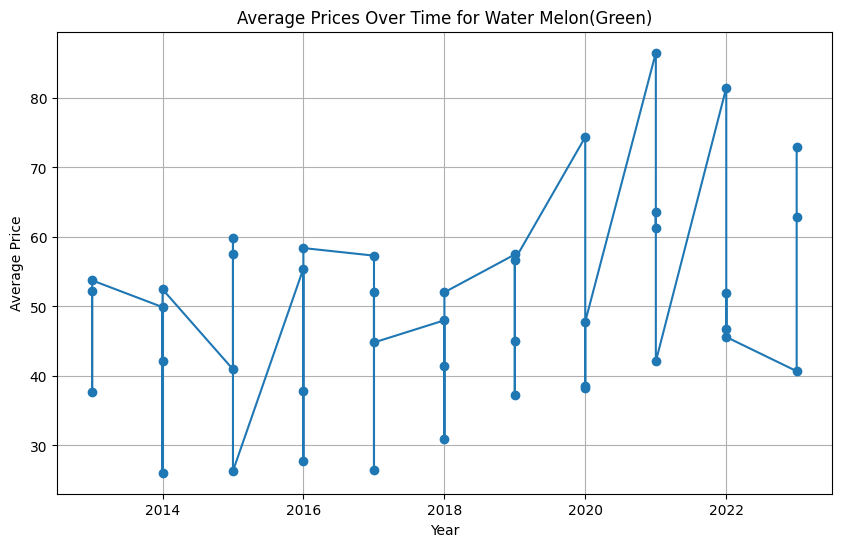

In [ ]:
# Filter the data for the selected commodity
selected_commodity = 'Water Melon(Green)'
commodity_data = seasonwise_aggregated_df[seasonwise_aggregated_df['Commodity'] == selected_commodity]

# Convert 'Season' column to datetime data type
commodity_data['Season'] = pd.to_datetime(commodity_data['Season'].str[:4], format='%Y')

# Sort the data by season
commodity_data = commodity_data.sort_values(by='Season')

# Plot the average prices over time
plt.figure(figsize=(10, 6))
plt.plot(commodity_data['Season'], commodity_data['Average'], marker='o', linestyle='-')
plt.title('Average Prices Over Time for {}'.format(selected_commodity))
plt.xlabel('Year')
plt.ylabel('Average Price')
plt.grid(True)
plt.show()


In [ ]:
# Filter the data for the desired commodity
commodity_name = 'Yam'
commodity_data = combined_df[combined_df['Commodity'] == commodity_name]

# Group by season and year, calculate average
season_year_avg = commodity_data.groupby(['Season', commodity_data['Date'].dt.year]).agg({'Average': 'mean'}).reset_index()

# Print the values obtained
for index, row in season_year_avg.iterrows():
    print(f"Season: {row['Season']}{row['Date']} | Average Price: {row['Average']}")

Season: 2013Autumn2013 | Average Price: 43.410714285714285
Season: 2013Winter2013 | Average Price: 27.869565217391305
Season: 2013Winter2014 | Average Price: 28.76086956521739
Season: 2014Autumn2014 | Average Price: 37.69767441860465
Season: 2014Spring2014 | Average Price: 32.358695652173914
Season: 2014Winter2014 | Average Price: 26.6
Season: 2014Winter2015 | Average Price: 27.451923076923077
Season: 2015Autumn2015 | Average Price: 39.14
Season: 2015Spring2015 | Average Price: 31.257142857142856
Season: 2015Winter2015 | Average Price: 30.35483870967742
Season: 2015Winter2016 | Average Price: 30.5
Season: 2016Autumn2016 | Average Price: 40.375
Season: 2016Spring2016 | Average Price: 27.933333333333334
Season: 2016Winter2016 | Average Price: 33.62903225806452
Season: 2016Winter2017 | Average Price: 44.96551724137931
Season: 2017Autumn2017 | Average Price: 51.37096774193548
Season: 2017Spring2017 | Average Price: 54.72222222222222
Season: 2017Winter2017 | Average Price: 37.5
Season: 2017

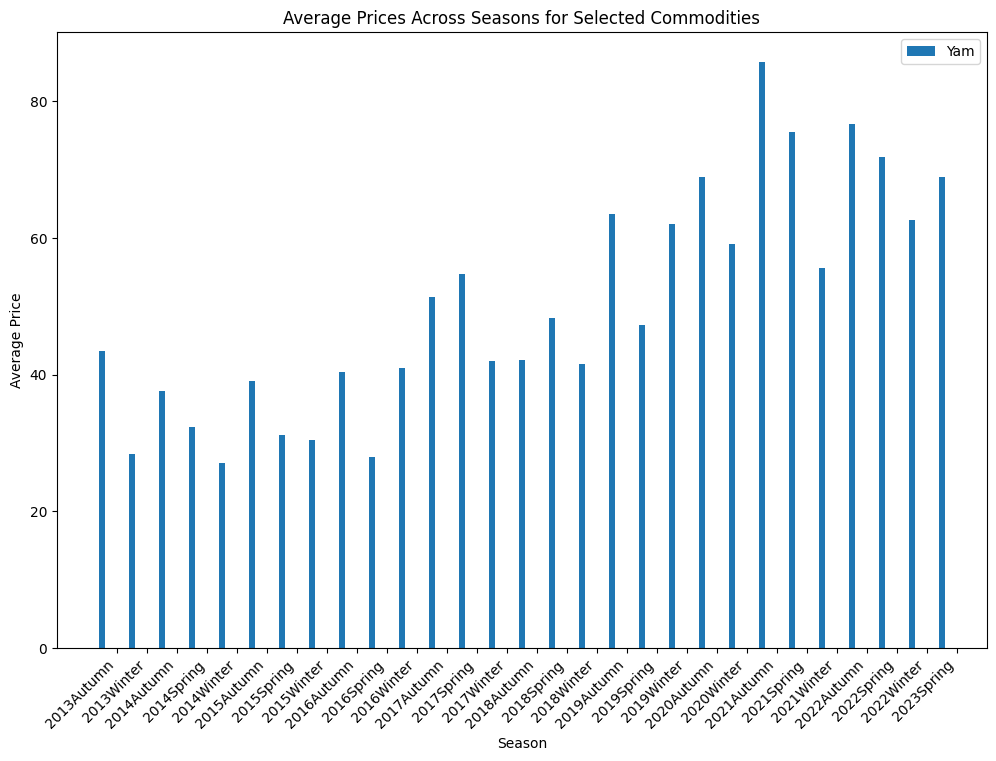

In [ ]:

selected_commodities = ['Yam']

# Filter the data for selected commodities
subset_data = seasonwise_aggregated_df[seasonwise_aggregated_df['Commodity'].isin(selected_commodities)]

# Set up the figure and axes
plt.figure(figsize=(12, 8))
ax = plt.subplot()

# Iterate over each selected commodity
for index, commodity in enumerate(selected_commodities):
    commodity_data = subset_data[subset_data['Commodity'] == commodity]

    # Convert 'Season' column to strings
    commodity_data.loc[:, 'Season'] = commodity_data['Season'].astype(str)

    # Create the bar plot
    ax.bar(commodity_data['Season'] , commodity_data['Average'], width=0.2, label=commodity)

# Set labels and title
ax.set_xlabel('Season')
ax.set_ylabel('Average Price')
ax.set_title('Average Prices Across Seasons for Selected Commodities')


# Adjust x-axis ticks and labels
ax.set_xticks([i + 0.5 for i in range(len(subset_data['Season'].unique()))])
ax.set_xticklabels(subset_data['Season'].unique(), rotation=45, ha='right')

# Add legend
ax.legend()

# Show plot
plt.show()


<ipython-input-203-44e029dfb323>:20: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation_matrix = seasonwise_aggregated_df.corr()


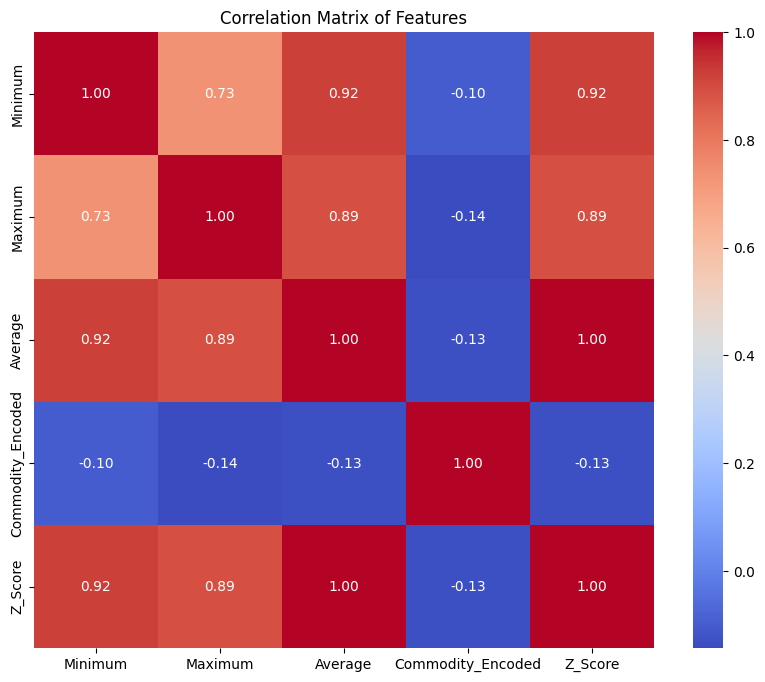

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from scipy.stats import zscore
from statsmodels.tsa.arima.model import ARIMA


# Encode Commodity column
label_encoder = LabelEncoder()
seasonwise_aggregated_df['Commodity_Encoded'] = label_encoder.fit_transform(seasonwise_aggregated_df['Commodity'])



# Correlation Analysis
# Calculate correlation matrix
correlation_matrix = seasonwise_aggregated_df.corr()

# Visualize correlation matrix using heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Features')
plt.show()

